In [1]:
!pip -q install librosa soundfile matplotlib numpy

In [2]:
import numpy as np
import librosa
import soundfile
import matplotlib.pyplot as plt

In [7]:
SR = 16000
N_FFT = 512
HOP_LENGTH = 1600
N_MELS = 64

def wczytaj_audio(sciezka="mixkit-little-birds-singing-in-the-trees-17.wav"):
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

y, sr = wczytaj_audio("mixkit-little-birds-singing-in-the-trees-17.wav")
print(f"Liczba próbek: {len(y)}")
print(f"Częstotliwość próbkowania: {sr} Hz")
print(f"Czas trwania: {len(y) / sr:.2f} s")

Liczba próbek: 95105
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 5.94 s


In [8]:
from IPython.display import Audio
Audio(y, rate=sr)

In [9]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

S_db = log_mel(y, sr)
M = mfcc(y, sr)
print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (64, 60)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 60)  (współczynniki × ramki czasowe)


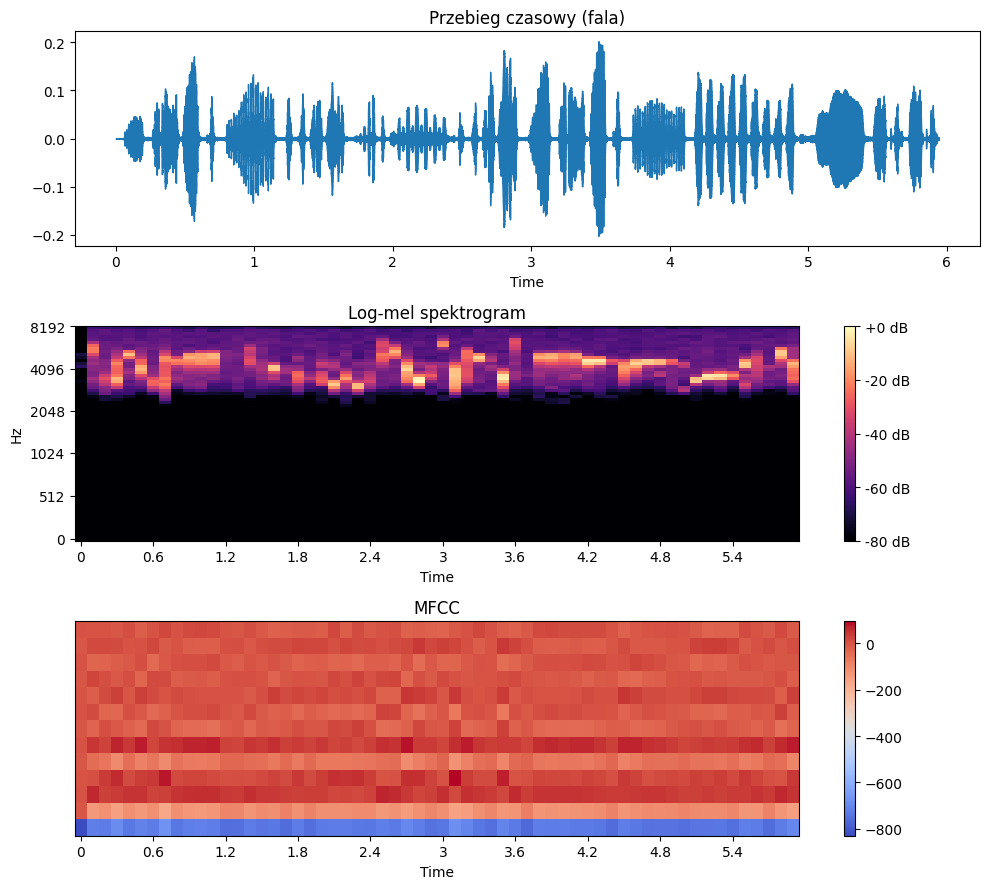

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala)")

img1 = librosa.display.specshow(
    S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

In [18]:
SR = 32000
N_FFT = 256
HOP_LENGTH = 80
N_MELS = 32

def wczytaj_audio(sciezka="samogloska.mp3"):
    if sciezka:
        y_sam, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y_sam.astype(np.float32), sr
    y_sam = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y_sam.astype(np.float32), SR

y_sam, sr = wczytaj_audio("samogloska.mp3")
S_sam = log_mel(y_sam, sr)
M_sam = mfcc(y_sam, sr)

print(f"Liczba próbek: {len(y_sam)}")
print(f"Częstotliwość próbkowania: {sr} Hz")
print(f"Czas trwania: {len(y_sam) / sr:.2f} s")

Liczba próbek: 13056
Częstotliwość próbkowania: 32000 Hz
Czas trwania: 0.41 s


In [19]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )
S_db = log_mel(y_sam, sr)
M = mfcc(y_sam, sr)
print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (32, 164)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 164)  (współczynniki × ramki czasowe)


In [20]:
Audio(y_sam, rate=sr)

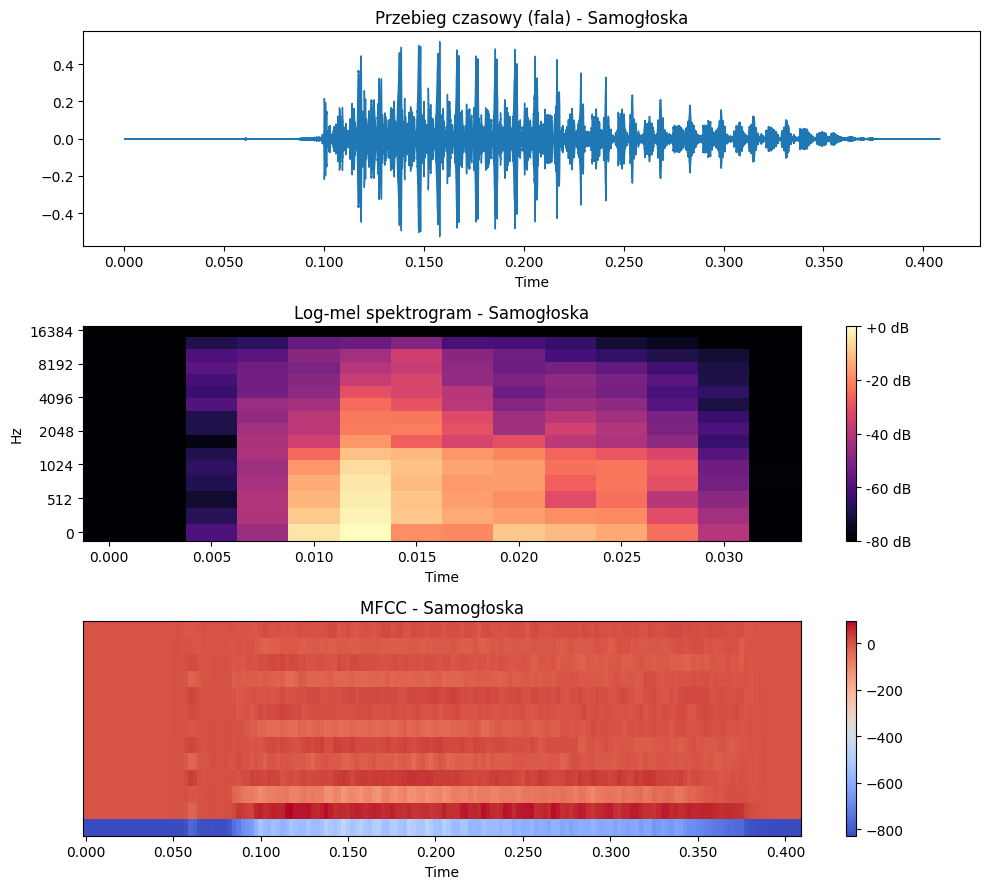

In [21]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y_sam, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala) - Samogłoska")

img1 = librosa.display.specshow(
    S_sam, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram - Samogłoska")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M_sam, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC - Samogłoska")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

Wyraz


In [22]:
SR = 8000
N_FFT = 128
HOP_LENGTH = 1000
N_MELS = 16

In [23]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )
def wczytaj_audio(sciezka="wyraz.mp3"):
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR
y_wyr, sr = wczytaj_audio("wyraz.mp3")
S_wyr = log_mel(y_wyr, sr)
M_wyr = mfcc(y_wyr, sr)
print(f"Kształt log-mel: {S_wyr.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M_wyr.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (16, 6)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 6)  (współczynniki × ramki czasowe)


In [24]:
Audio(y_wyr, rate=sr)

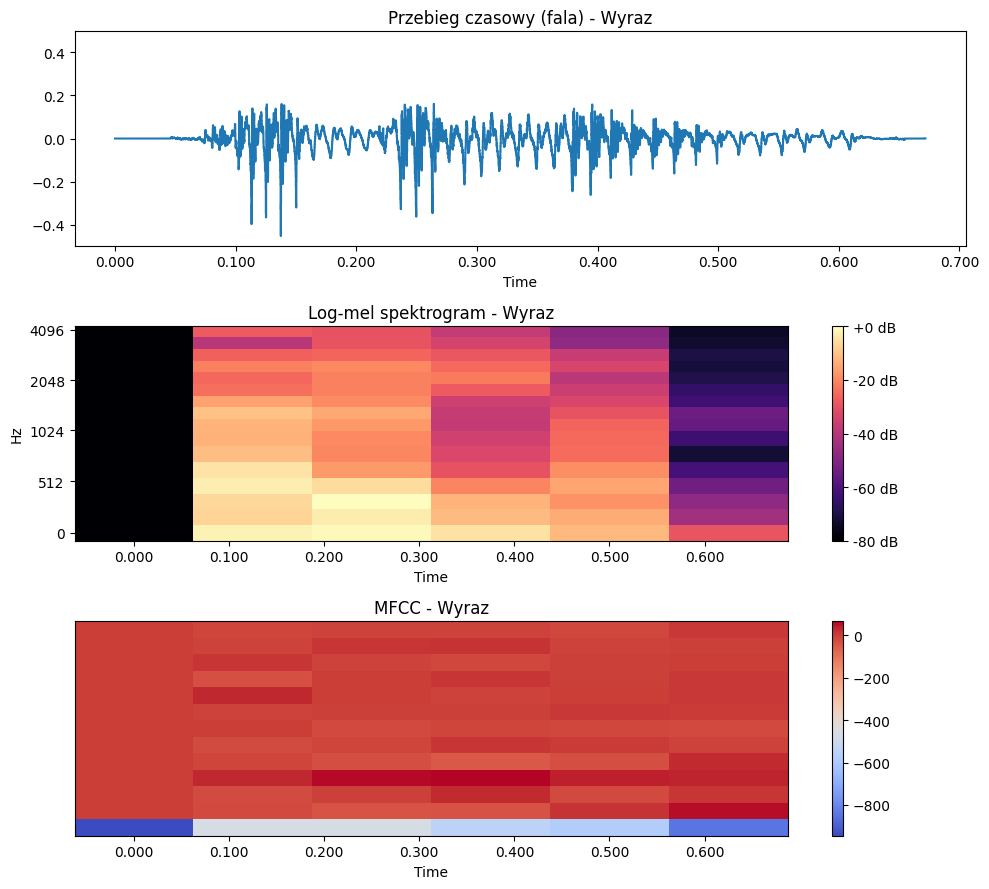

In [25]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y_wyr, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala) - Wyraz")

img1 = librosa.display.specshow(
    S_wyr, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram - Wyraz")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M_wyr, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC - Wyraz")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

Zdanie

In [30]:
SR = 8000
N_FFT = 64
HOP_LENGTH = 2000
N_MELS = 128

In [31]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )
def wczytaj_audio(sciezka="zdanie.mp3"):
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR
y_zdanie, sr = wczytaj_audio("zdanie.mp3")
S_zdanie = log_mel(y_zdanie, sr)
M_zdanie = mfcc(y_zdanie, sr)
print(f"Kształt log-mel: {S_zdanie.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M_zdanie.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (128, 7)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 7)  (współczynniki × ramki czasowe)


In [32]:
Audio(y_zdanie, rate=sr)

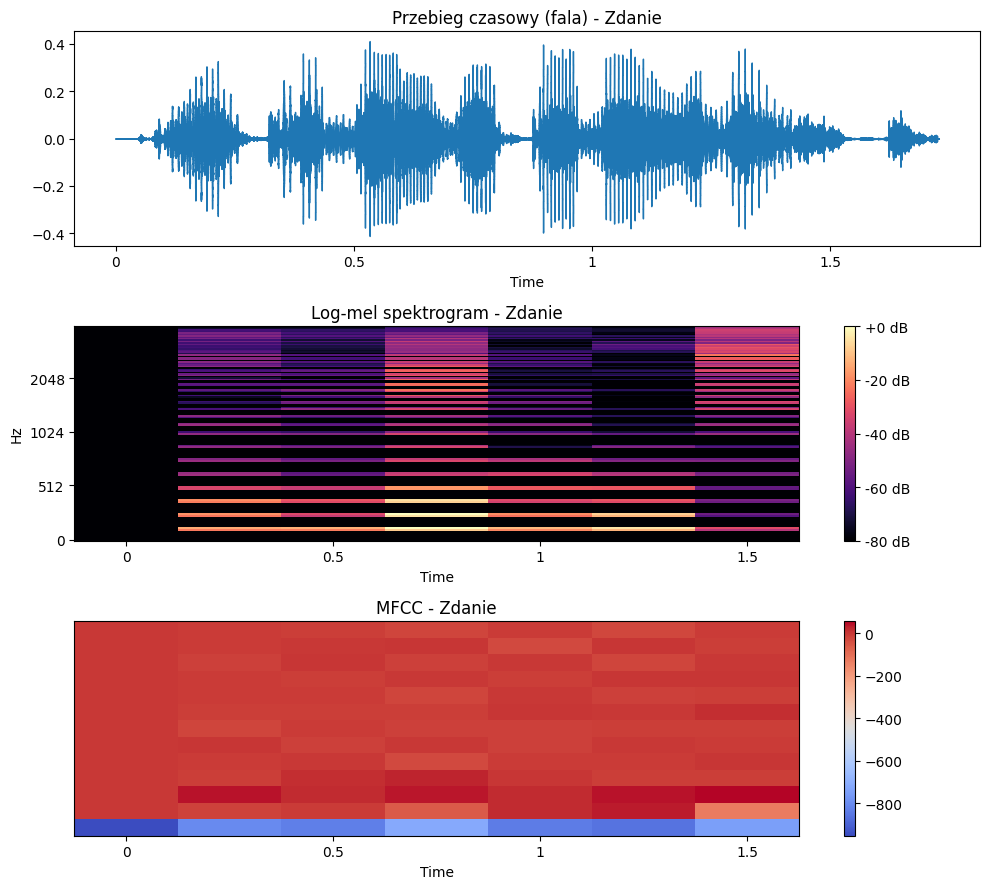

In [33]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y_zdanie, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala) - Zdanie")

img1 = librosa.display.specshow(
    S_zdanie, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram - Zdanie")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M_zdanie, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC - Zdanie")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()